# Sensitivity Analysis


This notebook explores **sensitivity analysis** of maintenance decision-making under different strategies and scenarios. The analysis uses various Python classes to model maintenance decisions, including both **Cost Minimization** and **Revenue Maximization** strategies. It evaluates the impact of changes in key parameters:

1. **Max Faults (`max_faults_range`)**:
   - The total number of faults expected, tested across a range of integer values to simulate different operational fault loads.

2. **High Seasonality (`high_seasonality_range`)**:
   - The proportion of faults occurring during high-demand seasons, tested across a spectrum from 0 (low seasonality) to 1 (high seasonality).

This notebook will perform the following:
- **Classes and Strategies**:
  - Implements classes for **Cost Minimization** (`MaintenanceStrategies_cost`, `MaintenanceStrategy_LinearOpt_cost`) and **Revenue Maximization** (`MaintenanceStrategies_revenue`).
  - Uses these classes to test maintenance decisions under varying conditions.

- **Scenarios**:
  - **Without Preventative Maintenance**: Evaluates maintenance decisions without fault reduction.
  - **With Preventative Maintenance**: Simulates scenarios with a 60% reduction in fault counts.

- **Decision Variables**:
  - Evaluates the preference for **internal vs. external maintenance** based on cost or revenue considerations.

- **Results Visualization**:
  - Generates threshold plots to illustrate the sensitivity of maintenance preferences to changes in `max_faults` and `high_seasonality`.

#### Objective:
The notebook tests the **sensitivity of maintenance decisions** to fault loads and seasonal variations to provide insights into optimal strategies for minimizing costs or maximizing revenue under different operational conditions.


In [1]:
from pyomo.environ import *
from pyomo.opt import SolverFactory
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


import sys
import os

# Get the path to the src folder
src_path = os.path.abspath(os.path.join(os.getcwd(), "../src"))
if src_path not in sys.path:
    sys.path.append(src_path)


from optimization import MaintenanceStrategies_cost
from optimization import MaintenanceStrategy_LinearOpt_cost
from optimization import MaintenanceStrategies_revenue


## Maintenance Strategy 1 (Minimize Maintenance Cost)

## **Using a Custom Class called MaintenanceStrategies_cost**

The `MaintenanceStrategies_cost` class is designed to determine the optimal maintenance strategy for minimizing total maintenance costs based on internal and external maintenance options. It incorporates factors such as fault rates, seasonal demand variations, and preventive maintenance effectiveness.

## Key Features

### 1. Initialization (`__init__` Method)
- **Parameters**:
  - `max_faults`: Maximum number of faults expected to occur.
  - `high_seasonality`: Proportion of faults occurring during the high-demand season (e.g., 0.7 indicates 70% faults happen in the high season).
  - `cost_internal`: Fixed cost for handling all faults internally.
  - `cost_external_normal`: Cost per fault for external maintenance during normal demand.
  - `cost_external_high_demand`: Cost per fault for external maintenance during high-demand seasons.
  - `prevention_effect`: Effectiveness of preventive maintenance in reducing fault occurrences.

- **Fault Distribution**:
  - Calculates the reduced number of faults after applying preventive measures (`faults_to_address`).
  - Splits faults into high-demand and normal seasons using the `high_seasonality` parameter.

### 2. Decision-Making (`maintenance_decsion` Method)
- **Cost Calculation**:
  - Compares the total cost of addressing faults externally (`total_external_cost`) with the fixed cost of internal maintenance (`cost_internal`).
  
- **Strategy Selection**:
  - If external maintenance is cheaper, faults are assigned to external providers, split across normal and high-demand seasons.
  - If internal maintenance is more cost-effective, all faults are addressed internally.

### 3. Outputs
- Returns the following:
  - `total_cost`: Total cost of the chosen maintenance strategy.
  - `total_internal_maintenance`: Number of faults addressed internally.
  - `total_external_normal_maintenance`: Number of faults addressed externally during the normal season.
  - `total_external_high_maintenance`: Number of faults addressed externally during the high-demand season.

### Without Any Preventation Maintenance

In [25]:

# Define integer values for faults_to_address
max_faults_range = np.arange(1, 100, 1)  # Integer steps
high_seasonality_range = np.linspace(0, 1, 20)  # Busy season ratios

# Storage for results
results = []

# Sensitivity analysis loop
for max_faults in max_faults_range:
    for high_seasonality in high_seasonality_range:
        sample_situation =MaintenanceStrategies_cost(max_faults, high_seasonality, prevention_effect=0)
        total_cost, x_internal, x_external_normal, x_external_high = sample_situation.maintenance_decsion()


        results.append({
            "Max Faults": max_faults,
            "High Seasonality": high_seasonality,
            "Internal Maintenance": x_internal,
            "External Maintenance (Normal)": x_external_normal,
            "External Maintenance (High-Demand)": x_external_high,
            "Total Cost": total_cost
        })


# Save results to a DataFrame and display
results_df = pd.DataFrame(results)

# Add a new column to indicate if internal maintenance is present
results_df["Internal Preference"] = results_df["Internal Maintenance"].apply(lambda x: True if x and x > 0 else False)

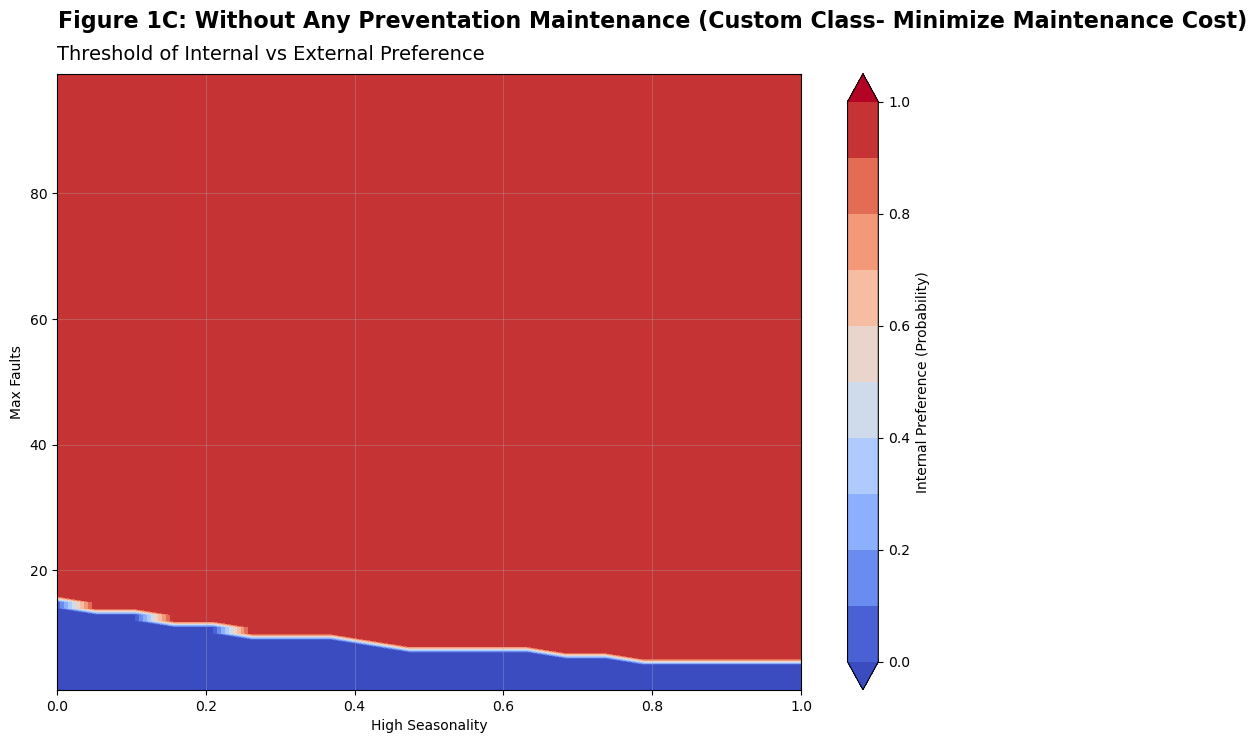

In [26]:
# Create a pivot table to visualize threshold values for internal preference
pivot_table = results_df.pivot_table(
    values='Internal Preference',
    index='High Seasonality',
    columns="Max Faults",
    aggfunc=np.mean
)

# Plotting the threshold chart with flipped axes
plt.figure(figsize=(12, 8))
c = plt.contourf(
    pivot_table.index,  # Flip axes: Use High Seasonality for x-axis
    pivot_table.columns,  # Use Faults to Address for y-axis
    pivot_table.values.T,  # Transpose the pivot table values
    levels=np.linspace(0, 1, 11),
    cmap='coolwarm',
    extend='both'
)
plt.colorbar(c, label='Internal Preference (Probability)')
plt.title(
    "Threshold of Internal vs External Preference",
    fontsize=14,
    pad=10,
    loc="left",
)

plt.suptitle(
    "Figure 1C: Without Any Preventation Maintenance (Custom Class- Minimize Maintenance Cost)",
    fontsize=16,
    fontweight="bold",
    x=0.126,
    y=0.96,
    ha="left",
)
plt.xlabel('High Seasonality')
plt.ylabel('Max Faults')
plt.grid(alpha=0.3)
plt.show()


The graph illustrates the **threshold of preference for internal vs. external maintenance strategies** based on two key variables:
1. **High Seasonality**: The proportion of faults occurring during high-demand seasons (x-axis).
2. **Max Faults**: The total number of faults expected (y-axis).

The color bar represents the **probability of choosing internal maintenance** as the optimal strategy, with:
- **0 (Blue Area)**: External maintenance preferred.
- **1 (Red Area)**: Internal maintenance preferred.

#### Observations

### 1. Dominance of Internal Maintenance (Red Area)
- **Trend**: As the **Max Faults** increases (higher y-axis values), internal maintenance becomes the dominant strategy.
- **Reason**: The fixed cost of internal maintenance is more economical for larger volumes of faults, as external maintenance costs scale linearly with fault count.

### 2. Preference for External Maintenance in Low-Fault Scenarios (Blue Area)
- **Trend**: When the **Max Faults** is low (near the bottom of the graph), external maintenance is more cost-effective, especially when faults are distributed across high-demand seasons.
- **Reason**: Internal maintenance costs remain fixed regardless of fault count, making it less favorable for smaller volumes of faults.

### 3. Impact of High Seasonality
- **Trend**: As **High Seasonality** increases (towards the right of the graph), external maintenance becomes more expensive due to the higher cost of high-demand season faults.
- **Observation**: Internal maintenance becomes favorable at higher fault volumes in high-seasonality scenarios, as the external cost surpasses the fixed internal cost.

### 4. Transition Zone (Gradient Area)
- **Observation**: The transition between blue and red regions represents scenarios where the cost difference between internal and external maintenance is marginal.
- **Reason**: The gradient reflects sensitivity to parameters like the cost of high-demand external maintenance and fault distribution.

#### Key Insights

1. **High Fault Volumes Favor Internal Maintenance**:
   - At higher `Max Faults`, internal maintenance is almost always preferred due to economies of scale in fixed costs.

2. **Low Fault Volumes and High Seasonality Favor External Maintenance**:
   - External maintenance is optimal for smaller fault counts, particularly when a significant proportion of faults occur during high-demand seasons.

3. **Threshold Sensitivity**:
   - The graph highlights the sensitivity of cost decisions to fault distribution and seasonal impact, emphasizing the need for accurate fault forecasting and cost estimation.

#### Practical Implications

Organizations should:
- Use **external maintenance** for small-scale fault scenarios, especially if the high seasonality proportion is significant.
- Opt for **internal maintenance** for high fault volumes to take advantage of fixed-cost economies.
- Consider **integrating preventive maintenance** (`prevention_effect > 0`) to reduce total faults and shift thresholds in favor of more economical strategies.

This analysis demonstrates how the model supports cost-minimization strategies under varying fault distributions and seasonal impacts. Let me know if you'd like to explore adjustments or alternative scenarios!


## **Using a Linear Solve Class called MaintenanceStrategy_LinearOpt_cost**


The `MaintenanceStrategy_LinearOpt_cost` class is a streamlined implementation of the `MaintenanceStrategies_cost` class. It is designed to **minimize maintenance costs** using a linear optimization approach with Pyomo and the Gurobi solver. This class determines the optimal maintenance strategy (internal vs. external) based on cost considerations.

---

#### Key Features

### 1. Inputs
- **Fault Parameters**:
  - `max_faults`: Total number of faults.
  - `high_seasonality`: Proportion of faults occurring during high-demand seasons.
- **Cost Parameters**:
  - `cost_internal`: Fixed cost for internal maintenance.
  - `cost_external_normal`: Cost per fault for external maintenance during normal seasons.
  - `cost_external_high_demand`: Cost per fault for external maintenance during high-demand seasons.
- **Prevention Effect**:
  - Reduces the fault burden by a specified proportion (`prevention_effect`).

### 2. Optimization Model
- **Decision Variable**:
  - `x_internal`: A binary variable indicating whether internal maintenance is chosen (`1`) or not (`0`).
- **Objective Function**:
  - Minimizes the total cost of handling faults, which includes:
    - External maintenance costs for faults during normal and high-demand seasons.
    - Internal maintenance fixed costs if chosen.
- **Seasonal Fault Distribution**:
  - Splits faults into high-demand and normal seasons to calculate external maintenance costs.

### 3. Solver
- Uses the Gurobi solver to determine the optimal maintenance decision that minimizes total costs.

### 4. Output
- A dictionary summarizing the results:
  - Faults handled internally and externally.
  - Maintenance costs for each strategy.
  - Total cost of the optimal strategy.



---

## Differences Between the Classes

| **Aspect**                | **`MaintenanceStrategies_cost`**             | **`MaintenanceStrategy_LinearOpt_cost`**           |
|---------------------------|----------------------------------------------|---------------------------------------------------|
| **Implementation**         | Direct cost comparison.                     | Uses linear optimization with Pyomo and Gurobi.  |
| **Approach**               | Manual comparison of costs for decisions.   | Automated optimization framework.                |
| **Conciseness**            | Requires more manual logic for calculations.| More concise and computationally efficient.      |
| **Solver Integration**     | Does not use an optimization solver.        | Explicitly integrates Gurobi for scalability.    |

---

## Summary

The `MaintenanceStrategy_LinearOpt_cost` class performs the same function as `MaintenanceStrategies_cost` but uses a linear optimization approach for simplicity and efficiency. Both classes provide the same decision-making framework for minimizing maintenance costs, but the linear optimization method is better suited for larger datasets and complex scenarios.


In [39]:
# Storage for results
results = []

# Sensitivity analysis loop
for max_faults in max_faults_range:
    for high_seasonality in high_seasonality_range:
        # Create an instance of the class
        strategy = MaintenanceStrategy_LinearOpt_cost(max_faults, high_seasonality, prevention_effect=0)
        
        # Solve the optimization problem and store the results
        results.append(strategy.solve())

# Convert results to a DataFrame for analysis
results_df = pd.DataFrame(results)


# Add a new column to indicate if internal maintenance is present
results_df["Internal Preference"] = results_df["Internal Maintenance"].apply(lambda x: True if x and x > 0 else False)

Read LP format model from file /var/folders/f1/tcfth2f16mv8s95myjjfx84h0000gn/T/tmpajn6_u_0.pyomo.lp
Reading time = 0.00 seconds
x1: 1 rows, 2 columns, 1 nonzeros
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (mac64[arm] - Darwin 22.6.0 22H313)

CPU model: Apple M1
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 1 rows, 2 columns and 1 nonzeros
Model fingerprint: 0x9b8bcfb4
Variable types: 1 continuous, 1 integer (1 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [5e+04, 7e+05]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 50000.000000

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 8 available processors)

Solution count 1: 50000 

Optimal solution found (tolerance 1.00e-04)
Best objective 5.000000000000e+04, best bound 5.000000000000e+04, gap 0.0000%
Read LP format model from file /var/fo

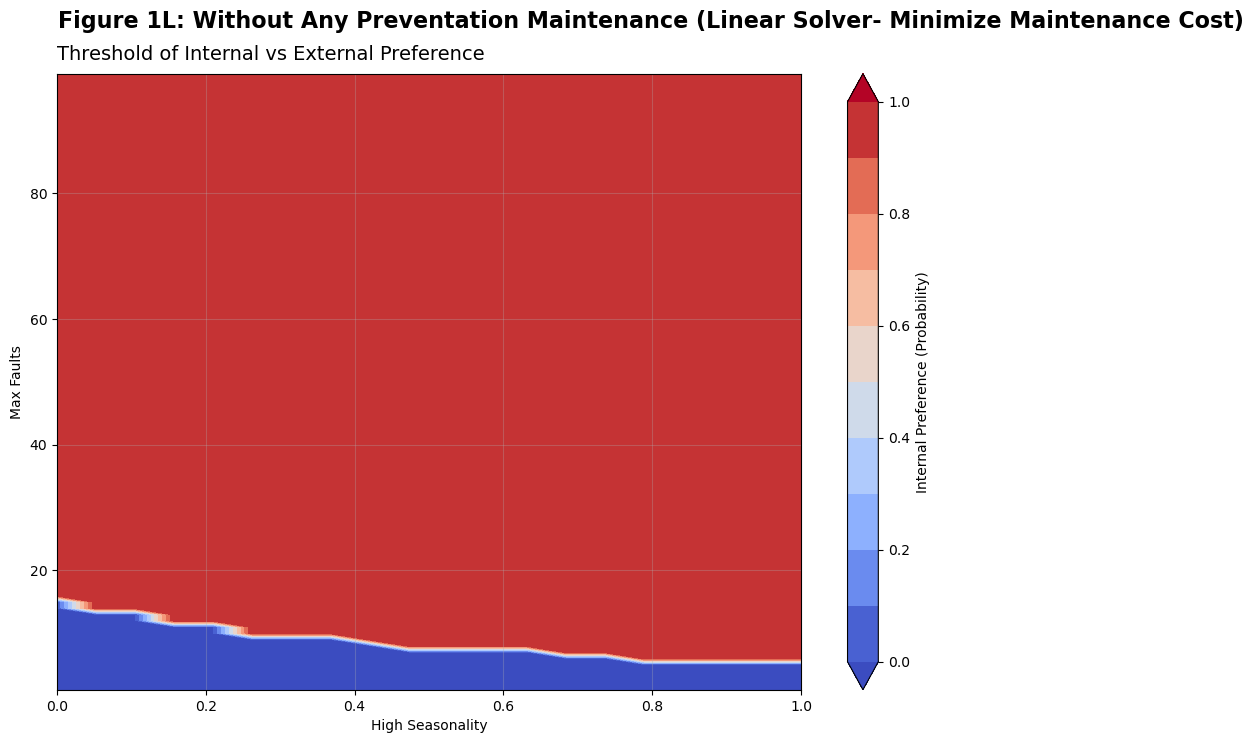

In [40]:
# Create a pivot table to visualize threshold values for internal preference
pivot_table = results_df.pivot_table(
    values='Internal Preference',
    index='High Seasonality',
    columns='Max Faults',
    aggfunc=np.mean
)

# Plotting the threshold chart with flipped axes
plt.figure(figsize=(12, 8))
c = plt.contourf(
    pivot_table.index,  # Flip axes: Use High Seasonality for x-axis
    pivot_table.columns,  # Use Faults to Address for y-axis
    pivot_table.values.T,  # Transpose the pivot table values
    levels=np.linspace(0, 1, 11),
    cmap='coolwarm',
    extend='both'
)
plt.colorbar(c, label='Internal Preference (Probability)')
plt.title(
    "Threshold of Internal vs External Preference",
    fontsize=14,
    pad=10,
    loc="left",
)

plt.suptitle(
    "Figure 1L: Without Any Preventation Maintenance (Linear Solver- Minimize Maintenance Cost)",
    fontsize=16,
    fontweight="bold",
    x=0.126,
    y=0.96,
    ha="left",
)
plt.xlabel('High Seasonality')
plt.ylabel("Max Faults")
plt.grid(alpha=0.3)
plt.show()



The graph generated using the `MaintenanceStrategy_LinearOpt_cost` class is **very similar** to the one generated by the `MaintenanceStrategies_cost` class. Both aim to minimize total maintenance costs, and since this scenario does not include preventative maintenance, the resulting trends and insights align closely.

---

#### Similar General Trends

1. **Dominance of Internal Maintenance (Red Area)**:
   - Internal maintenance dominates for higher fault counts across all levels of seasonality. This is due to the fixed cost of internal maintenance being more economical as the number of faults increases.

2. **Preference for External Maintenance (Blue Area)**:
   - External maintenance is preferred for very low fault counts, particularly at high seasonality levels where external costs remain competitive compared to the fixed internal cost.

3. **Narrow Transition Zone**:
   - The boundary between internal and external maintenance is sharp, reflecting the binary nature of cost comparison in both classes.

---

The graphs from both classes exhibit nearly identical results, confirming that the **linear optimization method** employed by the new class produces the same trends and insights as the **manual cost comparison** approach of the previous class. This validates the consistency and effectiveness of both methods in decision-making for maintenance cost minimization.


### With Preventation Maintenance (Resulting in 60% reduction in Faults)

## **Using a Custom Class called MaintenanceStrategies_cost**

In [29]:

# Storage for results
results = []

# Sensitivity analysis loop
for max_faults in max_faults_range:
    for high_seasonality in high_seasonality_range:
        sample_situation =MaintenanceStrategies_cost(max_faults, high_seasonality)
        total_cost, x_internal, x_external_normal, x_external_high = sample_situation.maintenance_decsion()


        results.append({
            "Max Faults": max_faults,
            "High Seasonality": high_seasonality,
            "Internal Maintenance": x_internal,
            "External Maintenance (Normal)": x_external_normal,
            "External Maintenance (High-Demand)": x_external_high,
            "Total Cost": total_cost
        })


# Save results to a DataFrame and display
results_df = pd.DataFrame(results)

# Add a new column to indicate if internal maintenance is present
results_df["Internal Preference"] = results_df["Internal Maintenance"].apply(lambda x: True if x and x > 0 else False)

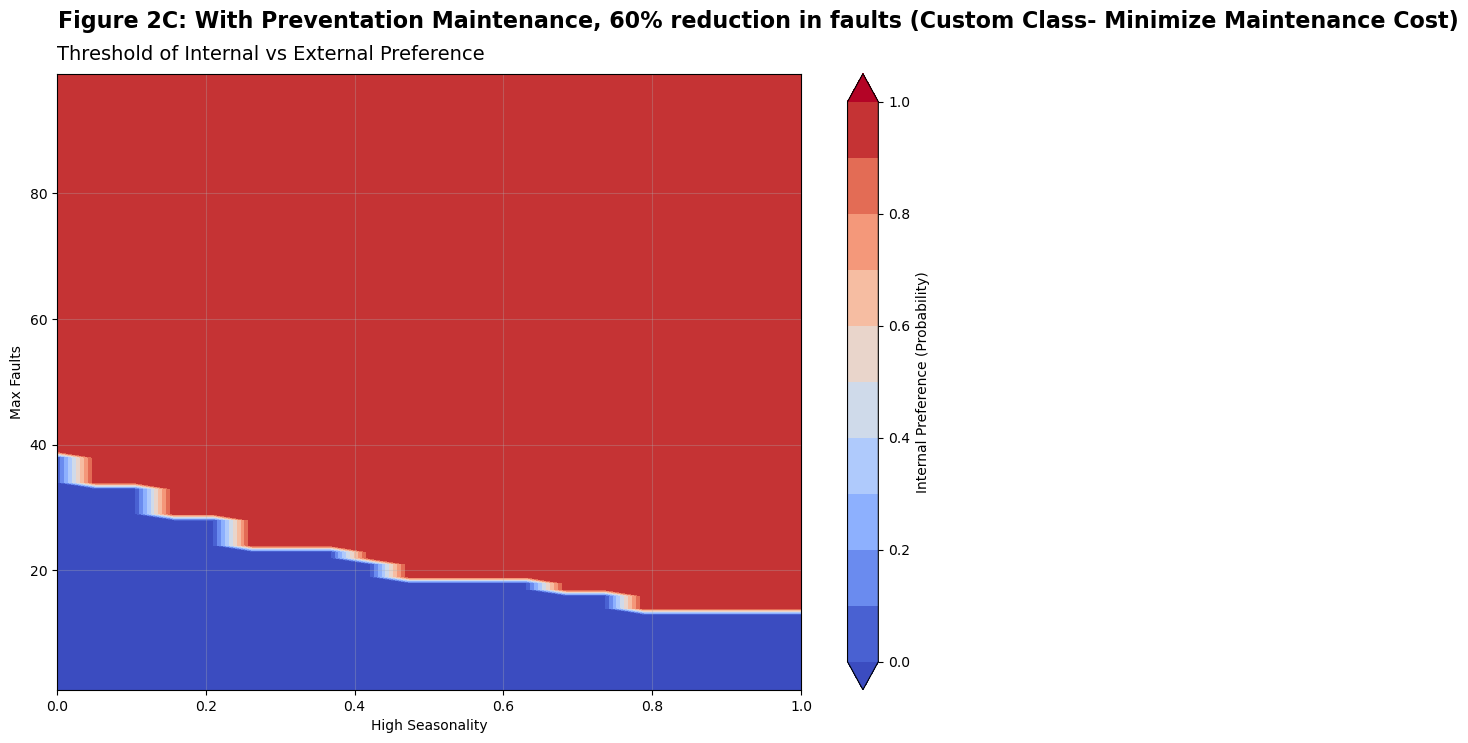

In [30]:
# Create a pivot table to visualize threshold values for internal preference
pivot_table = results_df.pivot_table(
    values='Internal Preference',
    index='High Seasonality',
    columns='Max Faults',
    aggfunc=np.mean
)

# Plotting the threshold chart with flipped axes
plt.figure(figsize=(12, 8))
c = plt.contourf(
    pivot_table.index,  # Flip axes: Use High Seasonality for x-axis
    pivot_table.columns,  # Use Faults to Address for y-axis
    pivot_table.values.T,  # Transpose the pivot table values
    levels=np.linspace(0, 1, 11),
    cmap='coolwarm',
    extend='both'
)
plt.colorbar(c, label='Internal Preference (Probability)')
plt.title(
    "Threshold of Internal vs External Preference",
    fontsize=14,
    pad=10,
    loc="left",
)

plt.suptitle(
    "Figure 2C: With Preventation Maintenance, 60% reduction in faults (Custom Class- Minimize Maintenance Cost)",
    fontsize=16,
    fontweight="bold",
    x=0.126,
    y=0.96,
    ha="left",
)
plt.xlabel('High Seasonality')
plt.ylabel('Max Faults')
plt.grid(alpha=0.3)
plt.show()



This graph evaluates the **threshold of preference for internal vs. external maintenance** after applying a **preventative maintenance strategy** that reduces faults by 60%.


### 1. Expansion of External Maintenance Preference (Blue Area)
- Compared to the previous graphes (Without Any Preventation Maintenance both Custom Class (Figure 1C) and Linear Solver (Figure 1L), the blue region (external maintenance preference) has expanded, particularly for lower **Max Faults** values.
- The reduced fault count due to preventative maintenance lowers the total cost of external maintenance, making it more favorable in scenarios with low fault volumes or high seasonality.

### 2. Persistence of Internal Maintenance Dominance (Red Area)
- At higher **Max Faults**, internal maintenance remains the dominant strategy (red area) because the fixed cost of internal maintenance becomes more economical for handling larger volumes of faults.
- However, this threshold occurs at a higher fault count than in the previous graph due to the overall fault reduction.

### 3. Impact of High Seasonality
- The transition to internal maintenance (from blue to red) happens at slightly higher **High Seasonality** values in this graph. This indicates that external maintenance during high-demand periods becomes less cost-effective only when fault volumes are sufficiently large.

### 4. Shifted Transition Zone
- The gradient area, where neither internal nor external maintenance is clearly dominant, has shifted to reflect a lower fault threshold compared to the previous graph. This highlights the cost benefits of fault reduction through preventative maintenance.

---

#### Comparison with the Previous Graph (Without Preventative Maintenance)

| **Aspect**                  | **Without Preventative Maintenance (Figure 2C)**               | **With Preventative Maintenance (Figure 1C and 1L)**                   |
|-----------------------------|---------------------------------------------------|---------------------------------------------------|
| **External Maintenance Preference** | Concentrated in lower fault ranges, especially with high seasonality. | Expanded due to the reduced fault count, making external maintenance cheaper. |
| **Internal Maintenance Preference** | Dominant for higher fault counts across all seasonality levels. | Still dominant but shifts to higher fault counts due to fault reduction. |
| **Transition Zone**         | Occurs at lower fault volumes but shifts quickly towards internal maintenance as fault count increases. | Occurs at slightly higher fault volumes and persists longer due to reduced overall faults. |
| **High Seasonality Impact** | Strongly favors external maintenance for low fault counts. | Still favors external maintenance but extends this preference to a wider fault range. |

---

#### Key Insights

1. **Effectiveness of Preventative Maintenance:**
   - Reducing fault counts by 60% increases the feasibility and cost-effectiveness of external maintenance, especially in low-fault scenarios.
   - The transition to internal maintenance occurs at higher fault volumes compared to the no-prevention scenario.

2. **Cost Trade-Offs:**
   - Preventative maintenance alters the fault distribution, making external maintenance a viable option for a wider range of scenarios, particularly for moderate seasonality levels.

3. **Seasonality and Fault Volume:**
   - High seasonality still raises external maintenance costs, but its impact is mitigated with preventative measures.

4. **Practical Implications:**
   - Preventative maintenance is particularly valuable for scenarios with smaller or moderate fault counts, as it reduces the reliance on costlier internal maintenance.

This analysis highlights how preventative strategies can shift cost thresholds, enabling more flexible and cost-effective maintenance decisions.


## **Using a Linear Solve Class called MaintenanceStrategy_LinearOpt_cost**

In [31]:
# Storage for results
results = []

# Sensitivity analysis loop
for max_faults in max_faults_range:
    for high_seasonality in high_seasonality_range:
        # Create an instance of the class
        strategy = MaintenanceStrategy_LinearOpt_cost(max_faults, high_seasonality)
        
        # Solve the optimization problem and store the results
        results.append(strategy.solve())

# Convert results to a DataFrame for analysis
results_df = pd.DataFrame(results)


# Add a new column to indicate if internal maintenance is present
results_df["Internal Preference"] = results_df["Internal Maintenance"].apply(lambda x: True if x and x > 0 else False)

Read LP format model from file /var/folders/f1/tcfth2f16mv8s95myjjfx84h0000gn/T/tmpysm7u7az.pyomo.lp
Reading time = 0.00 seconds
x1: 1 rows, 2 columns, 1 nonzeros
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (mac64[arm] - Darwin 22.6.0 22H313)

CPU model: Apple M1
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 1 rows, 2 columns and 1 nonzeros
Model fingerprint: 0x7ebcbfa8
Variable types: 1 continuous, 1 integer (1 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [8e+05, 8e+05]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 0.0000000

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 8 available processors)

Solution count 1: 0 

Optimal solution found (tolerance 1.00e-04)
Best objective 0.000000000000e+00, best bound 0.000000000000e+00, gap 0.0000%
Read LP format model from file /var/folders/f

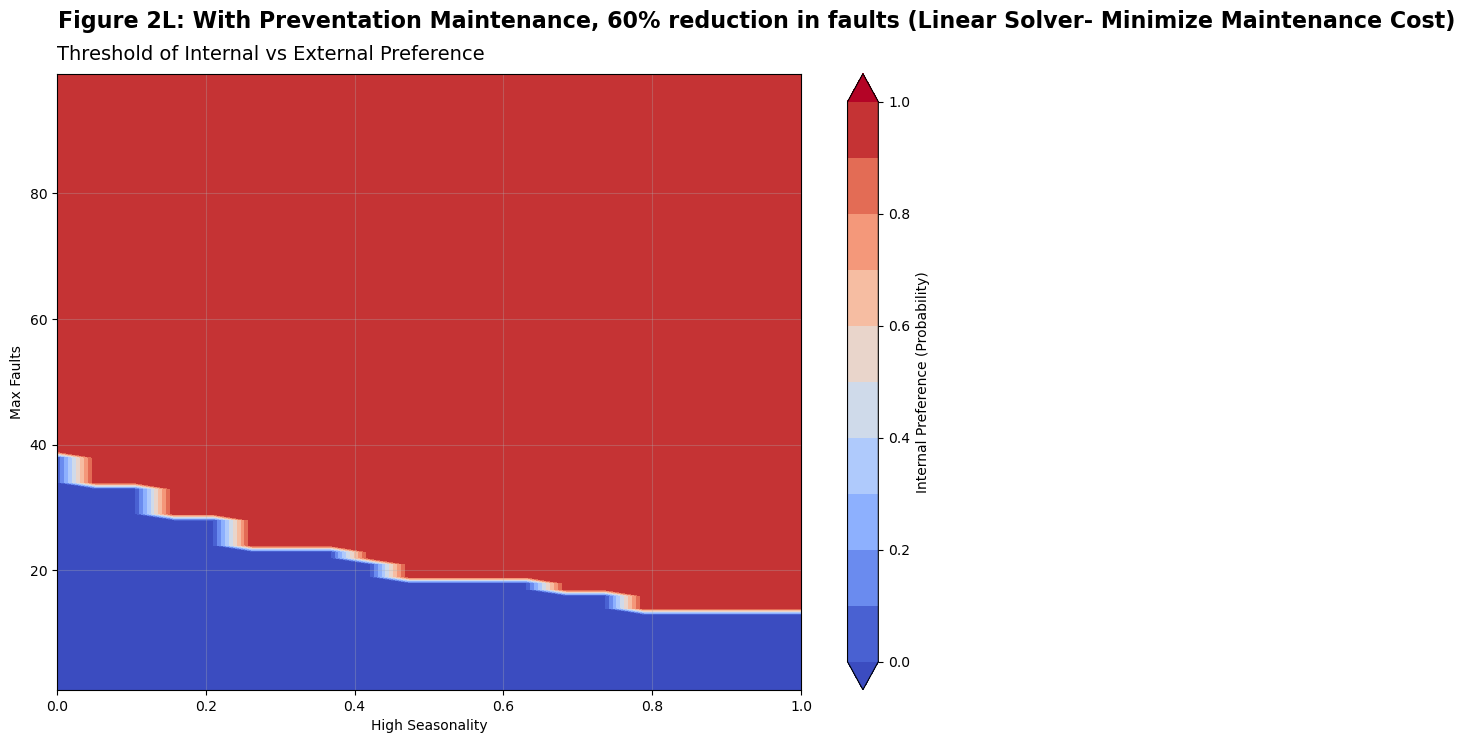

In [32]:
# Create a pivot table to visualize threshold values for internal preference
pivot_table = results_df.pivot_table(
    values='Internal Preference',
    index='High Seasonality',
    columns='Max Faults',
    aggfunc=np.mean
)

# Plotting the threshold chart with flipped axes
plt.figure(figsize=(12, 8))
c = plt.contourf(
    pivot_table.index,  # Flip axes: Use High Seasonality for x-axis
    pivot_table.columns,  # Use Faults to Address for y-axis
    pivot_table.values.T,  # Transpose the pivot table values
    levels=np.linspace(0, 1, 11),
    cmap='coolwarm',
    extend='both'
)
plt.colorbar(c, label='Internal Preference (Probability)')
plt.title(
    "Threshold of Internal vs External Preference",
    fontsize=14,
    pad=10,
    loc="left",
)

plt.suptitle(
    "Figure 2L: With Preventation Maintenance, 60% reduction in faults (Linear Solver- Minimize Maintenance Cost)",
    fontsize=16,
    fontweight="bold",
    x=0.126,
    y=0.96,
    ha="left",
)
plt.xlabel('High Seasonality')
plt.ylabel('Max Faults')
plt.grid(alpha=0.3)
plt.show()


The graph generated using the `MaintenanceStrategy_LinearOpt_cost` class, with **60% preventative maintenance fault reduction**, is **very similar** to the one generated by the `MaintenanceStrategies_cost` class. Both aim to minimize total maintenance costs and demonstrate consistent trends under the same conditions.

---

## Similar General Trends

1. **Expanded Preference for External Maintenance (Blue Area)**:
   - Preventative maintenance significantly reduces the fault count, increasing the feasibility of external maintenance.
   - External maintenance dominates for low to moderate fault counts, particularly at high seasonality levels.

2. **Dominance of Internal Maintenance (Red Area)**:
   - Internal maintenance remains the preferred strategy for very high fault counts, as the fixed cost becomes more economical for larger fault volumes.

3. **Shifted Transition Zone**:
   - The boundary between internal and external maintenance shifts to higher fault counts, reflecting the reduced fault burden from preventative maintenance.

---

## Conclusion

The results from both classes align closely, validating that the **linear optimization method** produces the same trends and decisions as the **manual cost comparison**. The inclusion of preventative maintenance shifts preferences toward external maintenance across more scenarios while maintaining similar overall patterns.


## Maintenance Strategy 2 (Maximize Revenue)


The `MaintenanceStrategies_revenue` class focuses on **maximizing revenue** while managing faults through either internal or external maintenance strategies. It takes into account maintenance costs, downtime, and the impact of preventive maintenance on reducing faults. The class calculates the total revenue generated based on the maintenance strategy and selects the option that results in the **highest revenue**.

---


### 1. Inputs and Parameters
- **Similar to `MaintenanceStrategies_cost`**:
  - `max_faults`: Maximum number of faults.
  - `high_seasonality`: Proportion of faults in high-demand seasons.
  - `cost_internal`: Fixed cost for internal maintenance.
  - `cost_external_normal`: Cost per fault for external maintenance in normal seasons.
  - `prevention_effect`: Reduction in faults due to preventive maintenance.

- **Additional Parameters**:
  - `repair_time_external_hr`: Time (in hours) to repair a fault using external maintenance.
  - `repair_time_internal_hr`: Time (in hours) to repair a fault using internal maintenance.
  - `operation_time_hr`: Total available operation time (in hours).
  - `max_revenue`: Maximum possible revenue achievable within the operation time.

---

### 2. Fault Reduction and Distribution
- **Preventive Maintenance**: Reduces total faults to address (`faults_to_address`) based on `prevention_effect`.
- **Seasonal Distribution**: Divides the remaining faults into high-demand and normal seasons using `high_seasonality`.

---

### 3. Revenue Calculations
- **Revenue for External Maintenance**:
  - Accounts for downtime due to external maintenance (`total_downtime_external_maintenance`) and its associated revenue loss.
  - Deducts external maintenance costs and lost revenue from the maximum possible revenue to compute `revenue_external_maintenance`.

- **Revenue for Internal Maintenance**:
  - Considers downtime caused by internal maintenance (`total_downtime_internal_maintenance`) and its revenue impact.
  - Deducts internal maintenance costs and lost revenue to compute `revenue_internal_maintenance`.

---

### 4. Decision Strategy (`maintenance_decision` Method)
- Compares the revenue generated by internal and external maintenance.
- Chooses the maintenance strategy that results in the **highest total revenue**.

---

## Comparison with `MaintenanceStrategies_cost`

| **Aspect**                       | **`MaintenanceStrategies_cost`**                     | **`MaintenanceStrategies_revenue`**                 |
|-----------------------------------|-----------------------------------------------------|-----------------------------------------------------|
| **Objective**                     | Minimize total maintenance cost.                   | Maximize total revenue.                            |
| **Key Factors in Decision**       | Direct cost comparison between internal and external maintenance. | Considers both maintenance costs and downtime, factoring in revenue loss. |
| **Impact of Downtime**            | Downtime is not explicitly considered.             | Downtime directly affects revenue calculations and decision-making. |
| **Decision Metric**               | Chooses the cheaper option between internal and external maintenance. | Chooses the option that generates the highest revenue. |
| **Output Metrics**                | Total cost, faults addressed by each strategy.      | Total revenue, downtime, cost, and faults handled by each strategy. |
| **Focus**                         | Pure cost minimization.                            | Balances cost, downtime, and revenue generation.    |

---

## Strategy for Deciding Internal vs. External Maintenance

### In `MaintenanceStrategies_cost`:
- **Focus**: Direct comparison of internal and external maintenance costs.
- **Decision**: Chooses the maintenance strategy (internal or external) that minimizes total cost, regardless of downtime or revenue impact.

### In `MaintenanceStrategies_revenue`:
- **Focus**: Balances cost with the impact of downtime on revenue.
- **Decision**:
  - External maintenance is preferred if its lower cost offsets the revenue lost due to its downtime.
  - Internal maintenance is chosen when its higher fixed cost is justified by the reduced downtime and the resulting higher revenue.

---

## Key Differences in Decision-Making

1. **Consideration of Downtime**:
   - `MaintenanceStrategies_revenue` explicitly incorporates downtime and its revenue impact into the decision process, unlike `MaintenanceStrategies_cost`.

2. **Revenue Maximization vs. Cost Minimization**:
   - The `MaintenanceStrategies_cost` class prioritizes minimizing expenses, making it suitable when downtime costs are negligible or fixed.
   - The `MaintenanceStrategies_revenue` class prioritizes maximizing operational revenue, making it suitable when downtime has a significant financial impact.

3. **Complexity of Decision**:
   - `MaintenanceStrategies_cost` decisions are simpler, based solely on cost comparisons.
   - `MaintenanceStrategies_revenue` involves a more nuanced decision-making process, requiring calculations of downtime, operational hours, and revenue loss.




### Without Any Preventation Maintenance

**Using a Custom Class called MaintenanceStrategies_revenue**

In [33]:
# Define integer values for faults_to_address
faults_to_address_range = np.arange(1, 4000, 1)  # Integer steps
high_seasonality_range = np.linspace(0, 1, 20)  # Busy season ratios

# Storage for results
results = []

# Sensitivity analysis loop
for max_faults in max_faults_range:
    for high_seasonality in high_seasonality_range:
        sample_situation =MaintenanceStrategies_revenue(max_faults, high_seasonality, prevention_effect=0)
        total_renvenue, total_downtime, total_cost, x_internal, x_external_normal, x_external_high = sample_situation.maintenance_decision()


        results.append({
            "Max Faults": max_faults,
            "High Seasonality": high_seasonality,
            "Internal Maintenance": x_internal,
            "External Maintenance (Normal)": x_external_normal,
            "External Maintenance (High-Demand)": x_external_high,
            "Total Cost": total_cost,
            "Total Downtime": total_downtime,
            "Total Revenue": total_renvenue
        })


# Save results to a DataFrame and display
results_df = pd.DataFrame(results)

# Add a new column to indicate if internal maintenance is present
results_df["Internal Preference"] = results_df["Internal Maintenance"].apply(lambda x: True if x and x > 0 else False)

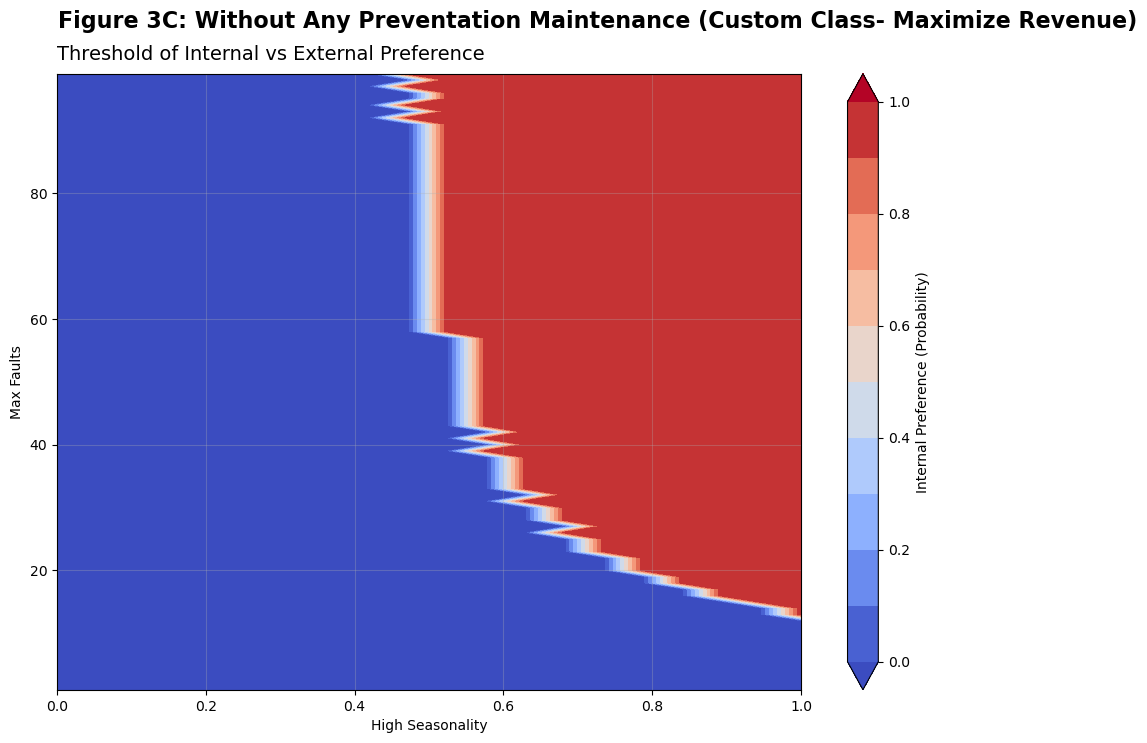

In [34]:
# Create a pivot table to visualize threshold values for internal preference
pivot_table = results_df.pivot_table(
    values='Internal Preference',
    index='High Seasonality',
    columns="Max Faults",
    aggfunc=np.mean
)

# Plotting the threshold chart with flipped axes
plt.figure(figsize=(12, 8))
c = plt.contourf(
    pivot_table.index,  # Flip axes: Use High Seasonality for x-axis
    pivot_table.columns,  # Use Faults to Address for y-axis
    pivot_table.values.T,  # Transpose the pivot table values
    levels=np.linspace(0, 1, 11),
    cmap='coolwarm',
    extend='both'
)
plt.colorbar(c, label='Internal Preference (Probability)')
plt.title(
    "Threshold of Internal vs External Preference",
    fontsize=14,
    pad=10,
    loc="left",
)

plt.suptitle(
    "Figure 3C: Without Any Preventation Maintenance (Custom Class- Maximize Revenue)",
    fontsize=16,
    fontweight="bold",
    x=0.126,
    y=0.96,
    ha="left",
)
plt.xlabel('High Seasonality')
plt.ylabel('Max Faults')
plt.grid(alpha=0.3)
plt.show()

The two graphs analyze **maintenance strategies without any prevention maintenance**, but they use different objective functions:
1. **Figure 1C and 1L**: Based on the `MaintenanceStrategies_cost` class, which focuses on **minimizing total maintenance cost**.
2. **Figure 3C**: Based on the `MaintenanceStrategies_revenue` class, which focuses on **maximizing total revenue**, factoring in downtime and operational revenue.

---

## Key Differences Between the Two Graphs

### 1. **Internal vs. External Preference Threshold**
- **Cost Minimization (Figure 1C and 1L)**:
  - Internal maintenance dominates (red area) for a wide range of fault volumes, even at low fault counts. This is because the fixed cost structure of internal maintenance is cheaper when faults increase.
  - External maintenance (blue area) is only preferred for very low fault counts and high seasonality.

- **Revenue Maximization (Figure 3C)**:
  - External maintenance dominates (blue area) for much larger regions, especially at lower fault counts. This is because downtime associated with internal maintenance (longer repair times) heavily impacts revenue.
  - Internal maintenance only becomes preferred at very high fault counts, as the revenue loss from downtime becomes negligible compared to the cost savings.

---

### 2. **Impact of High Seasonality**
- **Cost Minimization (Figure 1C and 1L)**:
  - High seasonality slightly shifts preference toward external maintenance, as faults during high-demand seasons make external costs escalate.
  - However, internal maintenance remains dominant for almost all fault levels.

- **Revenue Maximization**:
  - High seasonality significantly impacts external maintenance preference, as downtime in high-revenue periods heavily penalizes internal maintenance.
  - External maintenance dominates for a wider range of high seasonality, as its shorter repair time minimizes downtime costs.

---

### 3. **Transition Zone (Gradient Area)**
- **Cost Minimization (Figure 1C and 1L)**:
  - The transition zone is very narrow, reflecting a stark threshold where external maintenance is only briefly favored for extremely low fault counts.

- **evenue Maximization (Figure 3C)**:
  - The transition zone is much broader and jagged, showing nuanced trade-offs between downtime costs and repair costs as fault counts and seasonality change.

---

## Key Insights

### 1. **Impact of Downtime**
- The **revenue-based strategy** heavily penalizes internal maintenance for its longer downtime, making external maintenance more favorable for low and moderate fault levels.
- The **cost-based strategy** ignores downtime, leading to internal maintenance dominance across most scenarios.

### 2. **Seasonality Effect**
- Seasonality has a stronger impact on the **revenue-based strategy**, as downtime during high-demand seasons results in significant revenue loss, pushing the preference toward external maintenance.

### 3. **Threshold Behavior**
- The **cost-based strategy** shows a binary threshold for internal vs. external maintenance, as it relies solely on cost comparison.
- The **revenue-based strategy** displays a more dynamic and gradual transition zone, reflecting the complexity of balancing cost, downtime, and revenue.



### With Preventation Maintenance (Resulting in 60% reduction in Faults)

In [35]:
# Define integer values for faults_to_address
faults_to_address_range = np.arange(1, 4000, 1)  # Integer steps
high_seasonality_range = np.linspace(0, 1, 20)  # Busy season ratios

# Storage for results
results = []

# Sensitivity analysis loop
for max_faults in max_faults_range:
    for high_seasonality in high_seasonality_range:
        sample_situation =MaintenanceStrategies_revenue(max_faults, high_seasonality)
        total_renvenue, total_downtime, total_cost, x_internal, x_external_normal, x_external_high = sample_situation.maintenance_decision()


        results.append({
            "Max Faults": max_faults,
            "High Seasonality": high_seasonality,
            "Internal Maintenance": x_internal,
            "External Maintenance (Normal)": x_external_normal,
            "External Maintenance (High-Demand)": x_external_high,
            "Total Cost": total_cost,
            "Total Downtime": total_downtime,
            "Total Revenue": total_renvenue
        })


# Save results to a DataFrame and display
results_df = pd.DataFrame(results)

# Add a new column to indicate if internal maintenance is present
results_df["Internal Preference"] = results_df["Internal Maintenance"].apply(lambda x: True if x and x > 0 else False)

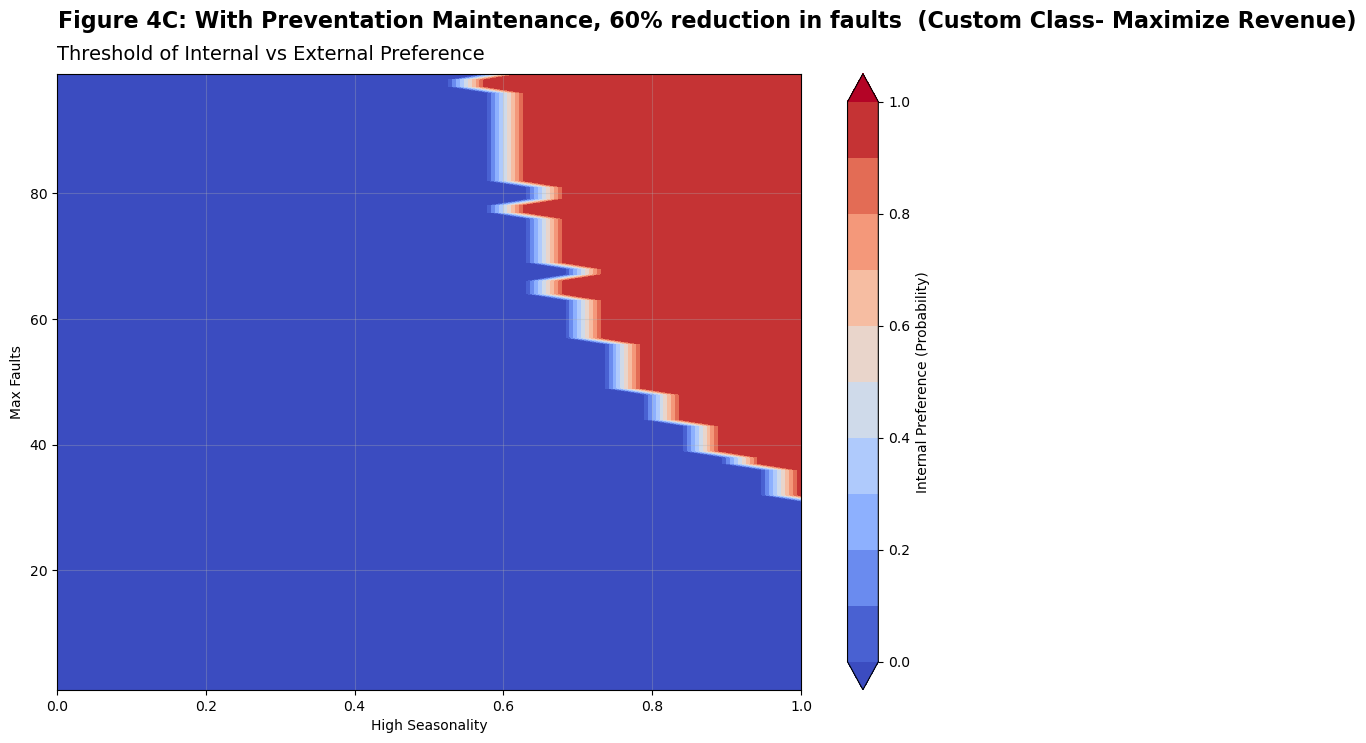

In [36]:
# Create a pivot table to visualize threshold values for internal preference
pivot_table = results_df.pivot_table(
    values='Internal Preference',
    index='High Seasonality',
    columns="Max Faults",
    aggfunc=np.mean
)

# Plotting the threshold chart with flipped axes
plt.figure(figsize=(12, 8))
c = plt.contourf(
    pivot_table.index,  # Flip axes: Use High Seasonality for x-axis
    pivot_table.columns,  # Use Faults to Address for y-axis
    pivot_table.values.T,  # Transpose the pivot table values
    levels=np.linspace(0, 1, 11),
    cmap='coolwarm',
    extend='both'
)
plt.colorbar(c, label='Internal Preference (Probability)')
plt.title(
    "Threshold of Internal vs External Preference",
    fontsize=14,
    pad=10,
    loc="left",
)

plt.suptitle(
    "Figure 4C: With Preventation Maintenance, 60% reduction in faults  (Custom Class- Maximize Revenue)",
    fontsize=16,
    fontweight="bold",
    x=0.126,
    y=0.96,
    ha="left",
)
plt.xlabel('High Seasonality')
plt.ylabel('Max Faults')
plt.grid(alpha=0.3)
plt.show()

# Analysis of Figure 4C vs. Figure 3C

This analysis compares two scenarios using the `MaintenanceStrategies_revenue` class, which focuses on **maximizing total revenue**:
1. **Figure 3C**: Without prevention maintenance.
2. **Figure 4C**: With prevention maintenance (resulting in a 60% reduction in faults).

---

## Observations and Key Differences

### 1. **Expansion of External Maintenance Preference (Blue Area)**
- **Without Prevention Maintenance (Figure 3C)**:
  - The blue area (external maintenance preference) dominates for low fault counts and high seasonality levels.
  - Internal maintenance (red area) becomes more favorable as fault counts increase, where the fixed costs of internal maintenance outweigh the revenue lost to downtime.

- **With Prevention Maintenance (Figure 4C)**:
  - The blue area has expanded significantly due to the reduced fault counts.
  - Even for higher fault counts, external maintenance remains the preferred strategy for a larger range of high seasonality levels.

### 2. **Impact of High Seasonality**
- **Figure 3C**:
  - High seasonality drives the preference toward external maintenance for low fault counts due to the significant revenue loss from downtime during peak demand periods.
  - Internal maintenance starts dominating at lower fault counts as seasonality increases.

- **Figure 4C**:
  - With 60% fewer faults, high seasonality has a much stronger effect, favoring external maintenance for a broader range of scenarios.
  - Internal maintenance is limited to extremely high fault counts or low seasonality.

### 3. **Shift in Transition Zone (Gradient Area)**
- **Without Prevention Maintenance**:
  - The transition zone (where neither internal nor external maintenance clearly dominates) occurs at mid-range fault levels, particularly as seasonality increases. The jagged boundary reflects the nuanced trade-offs between downtime costs and repair costs.

- **With Prevention Maintenance**:
  - The transition zone shifts significantly to the right (higher fault counts) and becomes narrower. This reflects the reduced fault burden, which makes external maintenance more cost-effective across a wider range of scenarios.

---

## Key Insights

### 1. **Effectiveness of Prevention Maintenance**
- Reducing faults by 60% significantly increases the feasibility and cost-effectiveness of external maintenance.
- The reduced fault burden minimizes the downtime and cost impact of external maintenance, making it the dominant strategy in most scenarios.

### 2. **Revenue Impact**
- Without prevention maintenance, downtime due to internal maintenance heavily impacts revenue, but it remains a viable option for high fault counts.
- With prevention maintenance, the revenue loss from downtime is drastically reduced, making external maintenance the preferred strategy across more fault ranges.

### 3. **Seasonality Sensitivity**
- High seasonality strongly favors external maintenance in both figures, but its effect is more pronounced with prevention maintenance. This is because fewer faults allow external maintenance to effectively minimize downtime during peak revenue periods.


# General Summary and Decision-Making Strategies for Maintenance Classes

This conclusion synthesizes the results from all scenarios analyzed using the `MaintenanceStrategies_cost` and `MaintenanceStrategies_revenue` classes. It considers both cases: **without preventative maintenance** and **with preventative maintenance** (60% fault reduction).

---

## Key Findings

### 1. **Cost Minimization (`MaintenanceStrategies_cost` Class)**

- **Without Preventative Maintenance**:
  - Internal maintenance dominates (red area) for most scenarios, as its fixed cost is more economical at higher fault counts.
  - External maintenance is only preferred for very low fault counts or in cases of high seasonality, where external costs remain low compared to the fixed internal cost.

- **With Preventative Maintenance**:
  - The reduction in fault counts makes external maintenance more viable for a broader range of scenarios.
  - Internal maintenance remains dominant at high fault counts but loses dominance for moderate fault levels due to the reduced burden on external maintenance costs.

- **Decision Strategy**:
  - Choose **internal maintenance** for scenarios with high fault counts, regardless of seasonality.
  - Opt for **external maintenance** for low fault counts or when faults are concentrated in high-demand seasons.

---

### 2. **Revenue Maximization (`MaintenanceStrategies_revenue` Class)**

- **Without Preventative Maintenance**:
  - External maintenance dominates (blue area) at low to moderate fault counts due to its shorter repair times, which minimize downtime and associated revenue loss.
  - Internal maintenance becomes preferable at very high fault counts, where the fixed cost outweighs downtime-induced revenue loss.

- **With Preventative Maintenance**:
  - External maintenance dominates for most scenarios, even at moderate fault counts, as the reduced downtime further enhances its revenue efficiency.
  - Internal maintenance is only viable in scenarios with extremely high fault counts, where fixed costs and minimized downtime losses offset the higher operational revenue requirements.

- **Decision Strategy**:
  - Prioritize **external maintenance** for most scenarios, especially at low to moderate fault counts or during high seasonality periods.
  - Use **internal maintenance** only for very high fault counts when the fixed cost is justified by reduced downtime.

---

## Comparison Between Classes

| **Aspect**                | **Cost Minimization**                                 | **Revenue Maximization**                             |
|---------------------------|-----------------------------------------------------|-----------------------------------------------------|
| **Primary Objective**      | Minimize maintenance costs.                         | Maximize operational revenue, factoring in downtime.|
| **Impact of Downtime**     | Ignored in decision-making.                         | Explicitly considered, heavily influencing decisions.|
| **Preference for Internal**| Dominant for high fault counts.                     | Limited to very high fault counts with minimal revenue loss.|
| **Preference for External**| Viable for low fault counts or high seasonality.     | Dominates most scenarios, especially with prevention.|
| **Effect of Prevention**   | Broadens external maintenance preference but still favors internal at high fault counts. | Makes external maintenance dominant across most scenarios.|



## Conclusion

- **For cost-driven strategies**, internal maintenance is more suitable for high fault counts, while external maintenance is ideal for low fault counts or high seasonality.
- **For revenue-driven strategies**, external maintenance dominates most scenarios due to its downtime advantage, with internal maintenance only viable for very high fault counts.
- **Preventative maintenance** is a key enabler for external maintenance, reducing fault burdens and enhancing operational efficiency.



### Assumptions of the Analysis

The analysis conducted in this notebook relies on several key assumptions. These assumptions impact the thresholds and decisions illustrated in the sensitivity analysis graphs. If these assumptions change, the outcomes and interpretations could vary significantly.

1. **Fixed Cost of Maintenance**:
   - The cost of **internal maintenance** is treated as a fixed expense, irrespective of the fault count.
   - External maintenance costs are proportional to the number of faults and are split between normal and high-demand season costs.

   **Impact**: If these costs were dynamic (e.g., bulk discounts for external maintenance or variable internal costs), the decision thresholds would shift.

---

 2. **Repair Downtime**:
   - **Internal Maintenance**:
     - Assumes a longer downtime due to in-house procedures and resource constraints.
   - **External Maintenance**:
     - Assumes a shorter downtime due to specialization or external expertise.

   **Impact**: Changes in the relative downtime between internal and external strategies would alter the preference for each strategy, particularly in the **Revenue Maximization** analysis where downtime directly affects revenue.

---

3. **Preventative Maintenance Cost is Missing**:
   - Preventative maintenance is assumed to reduce faults by a fixed proportion (60% in the scenarios analyzed), but it has no impact in the cost.

   **Impact**: If the Preventative maintenance has a signifcant cost it would have impact both strategies in this analysis as it would affect cost and reveune. 

---
 4. **Fault Distribution**:
   - Faults are distributed between high-demand and normal seasons based on a fixed `high_seasonality` proportion.
   - No additional complexity, such as varying fault severity or clustering, is modeled.

   **Impact**: Changes in fault distribution or inclusion of fault severity levels would require adjustments to external and internal maintenance strategies, potentially affecting costs and preferences.

---

 5. **Revenue Impact of Downtime**:
   - In the **Revenue Maximization** strategy, downtime directly reduces revenue in proportion to the total operation time and maximum possible revenue.
   - Assumes that downtime scales linearly with the number of faults addressed.

   **Impact**: If downtime has nonlinear effects (e.g., compounding losses during peak demand periods), the thresholds and preferences would shift.

---

6. **Focus on Binary Maintenance Decisions**:
   - Decisions are treated as binary (internal vs. external), with no intermediate options or shared responsibilities.

   **Impact**: Introducing mixed strategies (e.g., partial outsourcing) would make the decision-making process more complex and nuanced.

---


These assumptions simplify the analysis but also constrain the generalizability of the results. Future iterations of the analysis could incorporate dynamic costs, variable downtimes, or hybrid strategies to better reflect real-world scenarios. Acknowledging these assumptions highlights the sensitivity of the decisions to changes in key parameters and the importance of tailoring the analysis to specific operational contexts.
